In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [11]:
# --- подключение хелпера ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():      # если ноутбук лежит не в корне репозитория
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.helpers import save_fig, save_table

In [12]:
# --- 1. Wide-формат: строка = товар×магазин, колонки d_1..d_1913 = дни
sales = pd.read_csv(Path.cwd().parent / "data/raw/sales_train_validation.csv")
print(sales.shape)   # ожидаем (30490, 1919): 6 описателей + 1913 дней
print(sales[["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]].head())

(30490, 1919)
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  
0       CA  
1       CA  
2       CA  
3       CA  
4       CA  


In [13]:
# --- 2. Сколько уникальных сущностей в каждой размерности
print(
    f"Товаров: {sales["item_id"].nunique()}",
    f"\nМагазинов: {sales["store_id"].nunique()}",
    f"\nШтатов: {sales["state_id"].nunique()}"
)

Товаров: 3049 
Магазинов: 10 
Штатов: 3


In [14]:
# --- 3. Long-формат. Мелтим ОДИН магазин, а не весь файл — экономим память
day_cols = [c for c in sales.columns if c.startswith("d_")]
ca_1 = sales[sales["store_id"] == "CA_1"]
long_ca_1 = ca_1.melt(
    id_vars = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"],
    value_vars = day_cols,
    var_name = "d",         # из колонок d_1, d_2... получаем столбец 'd'
    value_name = "units",   # продано штук в этот день (наш target)
)
long_ca_1["units"] = long_ca_1["units"].astype("int16")   # int16 вместо int64: в 4 раза меньше памяти
print(long_ca_1.shape)                                    # (3049 * 1913, 8)

(5832737, 8)


In [15]:
# --- 4. Переводим d_1..d_1913 в настоящие даты через calendar.csv
cal = pd.read_csv(Path.cwd().parent / "data/raw/calendar.csv")
long_ca_1 = long_ca_1.merge(cal[["d", "date"]], on="d", how="left")
long_ca_1["date"] = pd.to_datetime(long_ca_1["date"])
print(long_ca_1["date"].min(), long_ca_1["date"].max())   # границы периода

2011-01-29 00:00:00 2016-04-24 00:00:00


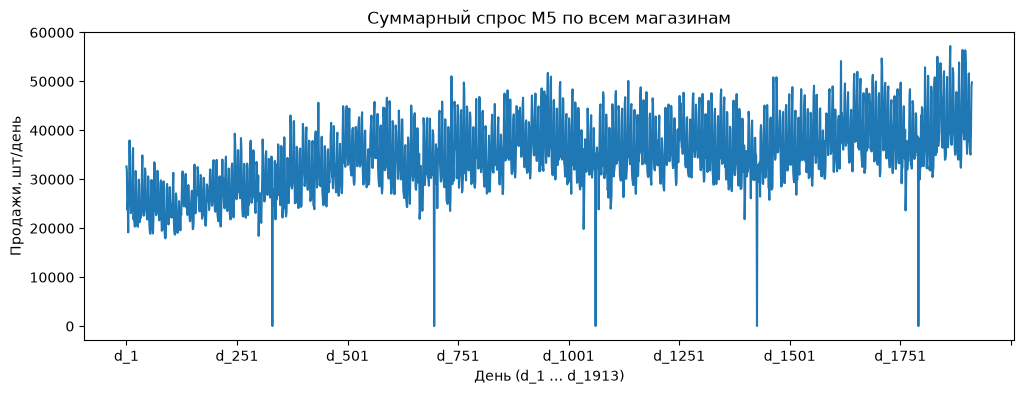

In [16]:
# Суммарный спрос всех магазинов по дням + сохранение графика
total_by_day = sales[day_cols].sum()

ax = total_by_day.plot(figsize=(12, 4))
ax.set_xlabel("День (d_1 … d_1913)")
ax.set_ylabel("Продажи, шт/день")
ax.set_title("Суммарный спрос M5 по всем магазинам")
save_fig(ax.figure, "01_data_total_by_day")

In [17]:
# Топ-5 магазинов
sales["total"] = sales[day_cols].sum(axis=1)

store_totals = sales.groupby("store_id")["total"].sum().sort_values(ascending=False)
top_5 = store_totals.head(5)
print(top_5)

store_id
CA_3    11188180
CA_1     7698216
TX_2     7214384
WI_2     6544012
WI_3     6427782
Name: total, dtype: int64


In [18]:
# Топ-5 магазинов + доли всех 10 магазинов (таблица с накопленной долей)
grand_total = sales["total"].sum()
share_top5 = top_5.sum() / grand_total
print(f"Топ-5 магазинов дают {share_top5:.1%} всех продаж")

top5_df = store_totals.reset_index()
top5_df.columns = ["store_id", "total_units"]
top5_df["share_%"] = (top5_df["total_units"] / grand_total * 100).round(1)
top5_df["cum_share_%"] = top5_df["share_%"].cumsum().round(1)
save_table(top5_df, "01_store_totals_share")

Топ-5 магазинов дают 59.5% всех продаж
